<a href="https://colab.research.google.com/github/Brokenstarck/Optativa-ia/blob/main/pr%C3%A1ctica_2_2_clustering_con_k_means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **K-means**

**K-means (k-medias)** es un algoritmo de aprendizaje automático no supervisado que divide un conjunto de datos en k grupos o clústeres basándose en la similitud de sus características.

Su principal limitación es que el usuario debe definir el valor de k inicialmente.

Este algoritmo se usa cuando tenemos datos sin etiquetas. Por ejemplo, medidas de flores (largo de pétalo, ancho de pétalo) pero no se sabe qué tipos de flores son. Se quiere descubrir cuántos tipos de flores hay.

En realidad, sí se conocen las tres especies, que luego usaremos para comparar el resultado obtenido: Iris **setosa**, Iris **versicolor** e Iris **virginica**.

Esto es aprendizaje no supervisado: no hay una respuesta correcta.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
print(type(iris))

<class 'sklearn.utils._bunch.Bunch'>


In [3]:
iris.feature_names
iris.target
#iris.target_names
#iris.DESCR

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [4]:
datos = iris.data
print(type(datos))
datos

<class 'numpy.ndarray'>


array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [5]:
# operaciones
primera_flor = datos[0]
primera_flor
un_valor = datos[5, 2]
un_valor
rango10a15 = datos[10:15]
rango10a15
rango0a3 = datos[:3]
rango0a3

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2]])

In [6]:
# se dispone de 150 datos, para cada uno 4 medidas
datos.shape

(150, 4)

In [7]:
from sklearn.cluster import KMeans

# === este es el número de grupos ===
n_clusters = 3
# =====================================

# se configura el modelo
modelo = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
# se entrena el modelo
modelo.fit(datos)

KMeans(n_clusters=3, n_init=10, random_state=0)

In [8]:
print(modelo.labels_)          # etiqueta de cluster (0, 1, 2...) de cada muestra
print(modelo.cluster_centers_) # coordenadas de los K centroides (shape: K × n_features)
print(modelo.inertia_)         # suma de distancias² (cómo de "compactos" son los clusters)
print(modelo.n_iter_)          # iteraciones que necesitó para converger

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]
[[5.9016129  2.7483871  4.39354839 1.43387097]
 [5.006      3.428      1.462      0.246     ]
 [6.85       3.07368421 5.74210526 2.07105263]]
78.851441426146
4


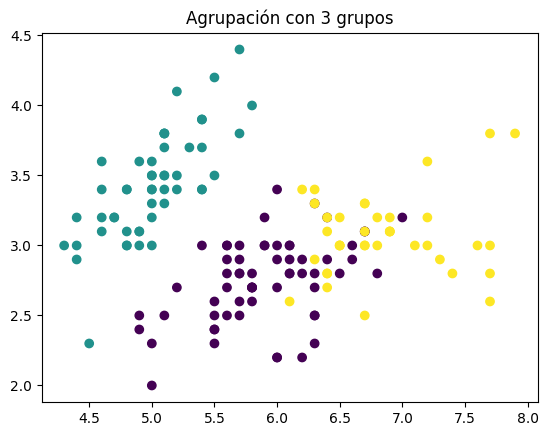

In [9]:
import matplotlib.pyplot as plt

plt.scatter(datos[:, 0], datos[:, 1], c=modelo.labels_, cmap="viridis")
plt.title(f"Agrupación con {n_clusters} grupos")
plt.show()

In [10]:
# prueba el código con 2 grupos
from sklearn.cluster import KMeans

# === este es el número de grupos ===
n_clusters = 2
# =====================================

# se configura el modelo
modelo = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
# se entrena el modelo
modelo.fit(datos)

KMeans(n_clusters=2, n_init=10, random_state=0)

In [11]:
# prueba el código con 4 grupos
from sklearn.cluster import KMeans

# === este es el número de grupos ===
n_clusters = 4
# =====================================

# se configura el modelo
modelo = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
# se entrena el modelo
modelo.fit(datos)

KMeans(n_clusters=4, n_init=10, random_state=0)

In [12]:
# prueba el código con 5 grupos
from sklearn.cluster import KMeans

# === este es el número de grupos ===
n_clusters = 5
# =====================================

# se configura el modelo
modelo = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
# se entrena el modelo
modelo.fit(datos)

KMeans(n_clusters=5, n_init=10, random_state=0)

**K-Means sirve para datos sin etiquetar, ¿qué datos reales llegan sin etiquetar en el mundo profesional?**

*Escribe aquí tu respuesta.*

En el mundo profesional existen muchísimos datos que se generan continuamente, pero que no tienen una etiqueta asignada. Por ejemplo:
1. Ejemplos reales en empresas
1. Comercio electrónico
- Historial de compras.
- Frecuencia de compra.
- Importe medio gastado.
- Productos consultados.

Una empresa puede utilizar K-Means para agrupar clientes según sus hábitos de consumo y crear perfiles como compradores habituales, compradores ocasionales o clientes de alto gasto.

El tipo de dato **numpy.ndarray** es un array de **NumPy**, para extraer fragmentos de datos debes usar coordenadas dentro de corchetes con la estructura:

datos[filas, columnas]

Los datos se pueden guardar en un array estructurado como si fuera una tabla de Excel con nombres en las columnas, lo ideal es transformarlo en un **DataFrame de Pandas**.


In [14]:
import pandas as pd

tabla = pd.DataFrame(datos, columns=iris.feature_names)
print(tabla.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [15]:
# también se puede importar los datos directamente,
# pero así no se dispone de los nombres de las columnas
tabla2 = pd.DataFrame(datos)
print(tabla2.head())

     0    1    2    3
0  5.1  3.5  1.4  0.2
1  4.9  3.0  1.4  0.2
2  4.7  3.2  1.3  0.2
3  4.6  3.1  1.5  0.2
4  5.0  3.6  1.4  0.2


In [16]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [17]:
tabla.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [18]:
tabla['petal length (cm)']

,petal length (cm)
0,1.4
1,1.4
2,1.3
3,1.5
4,1.4
...,...
145,5.2
146,5.0
147,5.2
148,5.4


In [19]:
flores_grandes = tabla[tabla['petal length (cm)'] > 5]
flores_grandes

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
83,6.0,2.7,5.1,1.6
100,6.3,3.3,6.0,2.5
101,5.8,2.7,5.1,1.9
102,7.1,3.0,5.9,2.1
103,6.3,2.9,5.6,1.8
104,6.5,3.0,5.8,2.2
105,7.6,3.0,6.6,2.1
107,7.3,2.9,6.3,1.8
108,6.7,2.5,5.8,1.8
109,7.2,3.6,6.1,2.5


In [20]:
# aquí se agregan tres columnas que representan el código de la especie,
# el nombre de la especie a la tabla y el código del cluster asignado
tabla['species'] = iris.target
tabla['species_name'] = tabla['species'].map(lambda x: iris.target_names[x])
tabla['cluster'] = modelo.labels_

In [21]:
tabla

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name,cluster
0,5.1,3.5,1.4,0.2,0,setosa,1
1,4.9,3.0,1.4,0.2,0,setosa,1
2,4.7,3.2,1.3,0.2,0,setosa,1
3,4.6,3.1,1.5,0.2,0,setosa,1
4,5.0,3.6,1.4,0.2,0,setosa,1
...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,virginica,3
146,6.3,2.5,5.0,1.9,2,virginica,4
147,6.5,3.0,5.2,2.0,2,virginica,3
148,6.2,3.4,5.4,2.3,2,virginica,3


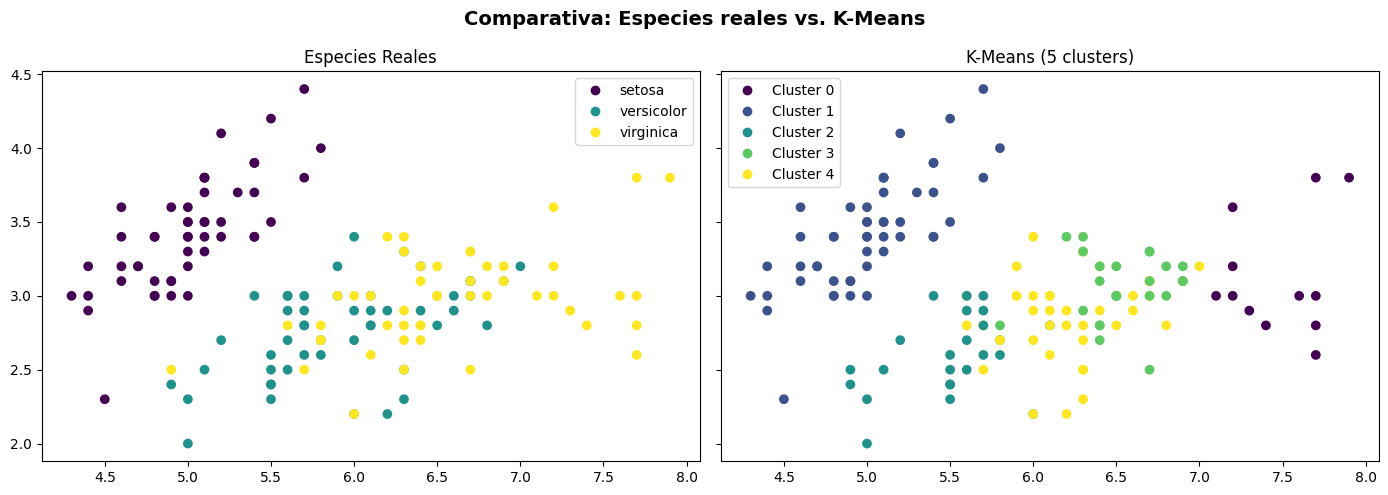

In [22]:
# para comparar el resultado con las especies realesn_clusters = 3

# creamos una figura con 2 gráficos enfrentados (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

scatter1 = ax1.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['species'],
    cmap='viridis'
)
ax1.set_title("Especies Reales")
ax1.legend(handles=scatter1.legend_elements()[0], labels=list(iris.target_names))

scatter2 = ax2.scatter(
    tabla['sepal length (cm)'],
    tabla['sepal width (cm)'],
    c=tabla['cluster'],
    cmap='viridis'
)
ax2.set_title(f"K-Means ({n_clusters} clusters)")
ax2.legend(handles=scatter2.legend_elements()[0], labels=[f'Cluster {i}' for i in range(n_clusters)])

plt.suptitle("Comparativa: Especies reales vs. K-Means", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [23]:
# para comparar el resultado con las especies reales
print(modelo.labels_)
print(iris.target)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 4 4 4 2 4 4 4 2 4 2 2 4 2 4 2 4 4 2 4 2 4 2 4 4
 4 4 4 4 4 2 2 2 2 4 2 4 4 4 2 2 2 4 2 2 2 2 2 4 2 2 3 4 0 3 3 0 2 0 3 0 3
 3 3 4 3 3 3 0 0 4 3 4 0 4 3 0 4 4 3 0 0 0 3 4 4 0 3 3 4 3 3 3 4 3 3 3 4 3
 3 4]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


Implementa una comparación entre los resultados obtenidos y los resultados reales.

In [24]:
# aquí va la implementación

from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import confusion_matrix
import pandas as pd

# Cargar datos reales
iris = load_iris()
X = iris.data[:, :2]
y_real = iris.target

# Aplicar K-Means con 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
resultado_kmeans = kmeans.fit_predict(X)

# Comparar resultados
ari = adjusted_rand_score(y_real, resultado_kmeans)

# Crear tabla comparativa
tabla = pd.crosstab(
    pd.Series(y_real, name="Especie real"),
    pd.Series(resultado_kmeans, name="Cluster K-Means")
)

print("=== COMPARACIÓN DE RESULTADOS ===")
print(tabla)

# Calcular pureza de los clusters
pureza = tabla.max(axis=0).sum() / tabla.values.sum()

print("\nÍndice Adjusted Rand (ARI):", round(ari, 3))
print("Pureza de los clusters:", round(pureza * 100, 2), "%")


=== COMPARACIÓN DE RESULTADOS ===
Cluster K-Means   0   1   2   3   4
Especie real                       
0                32   0  18   0   0
1                 0  14   5  30   1
2                 0  27   1  10  12

Índice Adjusted Rand (ARI): 0.373
Pureza de los clusters: 79.33 %
